In [1]:
## Imports
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from metpy.units import units
import metpy.constants as constants
import geocat.viz as gv
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [2]:
# Variable selections
variab = ['mse_vint','cp','v', 'pv', 'dse_vint']

varNam = ['mse_vint_prime','CP_prime','V_prime', 'PV_prime', 'dse_vint_prime']

itrack = [5,3,1]

# Selections:
level = [850,600]
stormTracks = ['N', 'N', 'O'],['S', 'S', 'O']
Ltitle = ['Northern Track', 'Southern Track']
label = ['(a) ','(b) ','(c) '], ['(d) ','(e) ','(f) ']

# Three track points: Ocean, S, & N (respectively)
stormTrackLons = [-34., 14., 14.]
stormTrackLats = [12., 8., 21.5]

deltaLon = 1  #box average
deltaLat = 1
dt = 6*3600 # 6 hour delta


In [3]:
path_composite = '/glade/derecho/scratch/aiyyer/mse/composites/refV'
#plotsdir = '/glade/u/home/athornton/plots/timeseries/'

In [4]:
def get_data(variab, level, itrack, varNam):
    print('level:', level)
    print('itrack:', itrack)
    print('variab:', variab)
    print('varNam:', varNam)
    if variab in ['v', 'pv']:
        ds = xr.open_dataset(path_composite+str(level)+'/'+variab+'_'+str(level)+'_Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(itrack)+'.nc')
    else:
        ds = xr.open_dataset(path_composite+str(level)+'/'+variab+'_Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(itrack)+'.nc')
    lonRef = ds.Reflon.values
    latRef = ds.Reflat.values
    var = ds[varNam].sel(latitude=slice(latRef+deltaLat, latRef-deltaLat), 
                                    longitude=slice(lonRef-deltaLon, lonRef+deltaLon)).metpy.quantify()
    var_mean = var.mean(dim=['latitude', 'longitude'])
    var_mean = var_mean.sel(Lag=slice(-66,66))
    var_mean.attrs['lonRef'] = lonRef
    var_mean.attrs['latRef'] = latRef
    return var_mean #lonRef, latRef

In [5]:
precip = get_data(variab[1], level[0], itrack[2], varNam[1])
precip = precip*constants.density_water*constants.water_heat_vaporization
precip = precip.metpy.convert_units('watts/(m**2)')

precip.max()

level: 850
itrack: 1
variab: cp
varNam: CP_prime


<xarray.DataArray 'CP_prime' ()> Size: 8B
<Quantity(216.696687, 'watt / meter ** 2')>
Coordinates:
    level    float64 8B ...

In [6]:
precip = get_data(variab[1], level[1], itrack[0], varNam[1])
precip = precip*constants.density_water*constants.water_heat_vaporization
precip = precip.metpy.convert_units('watts/(m**2)')

precip.max()

level: 600
itrack: 5
variab: cp
varNam: CP_prime


<xarray.DataArray 'CP_prime' ()> Size: 8B
<Quantity(154.605708, 'watt / meter ** 2')>
Coordinates:
    level    float64 8B ...

In [7]:
precip = get_data(variab[1], level[0], itrack[2], varNam[1])
precip = precip*constants.density_water*constants.water_heat_vaporization
precip = precip.metpy.convert_units('watts/(m**2)')

precip.max()

level: 850
itrack: 1
variab: cp
varNam: CP_prime


<xarray.DataArray 'CP_prime' ()> Size: 8B
<Quantity(216.696687, 'watt / meter ** 2')>
Coordinates:
    level    float64 8B ...

level: 850
itrack: 5
variab: mse_vint
varNam: mse_vint_prime
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(-8069071.59, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE min:
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(11562615.7, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE max:
-145.5240333661483 tend min:
191.08328702530034 tend max:
level: 850
itrack: 5
variab: pv
varNam: PV_prime
level: 850
itrack: 5
variab: cp
varNam: CP_prime
level: 850
itrack: 5
variab: v
varNam: V_prime
level: 850
itrack: 5
variab: dse_vint
varNam: dse_vint_prime
level: 850
itrack: 3
variab: mse_vint
varNam: mse_vint_prime


/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:395: UserWarning: The `map_projection` keyword argument is deprecated, use `projection` to instantiate a GeoAxes instead.
  warnings.warn("The `map_projection` keyword argument is "


<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(-9468687.8, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE min:
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(12796861.9, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE max:
-136.65053161194345 tend min:
204.59623387141275 tend max:
level: 850
itrack: 3
variab: pv
varNam: PV_prime
level: 850
itrack: 3
variab: cp
varNam: CP_prime
level: 850
itrack: 3
variab: v
varNam: V_prime
level: 850
itrack: 3
variab: dse_vint
varNam: dse_vint_prime


/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:395: UserWarning: The `map_projection` keyword argument is deprecated, use `projection` to instantiate a GeoAxes instead.
  warnings.warn("The `map_projection` keyword argument is "


level: 850
itrack: 1
variab: mse_vint
varNam: mse_vint_prime
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(-7143253.38, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE min:
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(10577602.5, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE max:
-135.73380476576972 tend min:
178.55550422311893 tend max:
level: 850
itrack: 1
variab: pv
varNam: PV_prime
level: 850
itrack: 1
variab: cp
varNam: CP_prime
level: 850
itrack: 1
variab: v
varNam: V_prime
level: 850
itrack: 1
variab: dse_vint
varNam: dse_vint_prime


/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:395: UserWarning: The `map_projection` keyword argument is deprecated, use `projection` to instantiate a GeoAxes instead.
  warnings.warn("The `map_projection` keyword argument is "


... (2 outputs left out)

<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(-4535215.67, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE min:
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(6469443.27, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE max:
-128.0986182731291 tend min:
101.86384060098958 tend max:
level: 600
itrack: 3
variab: pv
varNam: PV_prime
level: 600
itrack: 3
variab: cp
varNam: CP_prime
level: 600
itrack: 3
variab: v
varNam: V_prime
level: 600
itrack: 3
variab: dse_vint
varNam: dse_vint_prime
level: 600
itrack: 1
variab: mse_vint
varNam: mse_vint_prime
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(-6441496.63, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE min:
<xarray.DataArray 'mse_vint_prime' ()> Size: 8B
<Quantity(10874466.4, 'joule / meter ** 2')>
Coordinates:
    level    float64 8B ... MSE max:
-160.51932081011614 tend min:
181.13853304668103 tend max:
level: 600
itrack: 1
variab: pv
varNam: PV

/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:395: UserWarning: The `map_projection` keyword argument is deprecated, use `projection` to instantiate a GeoAxes instead.
  warnings.warn("The `map_projection` keyword argument is "


level: 600
itrack: 1
variab: cp
varNam: CP_prime
level: 600
itrack: 1
variab: v
varNam: V_prime
level: 600
itrack: 1
variab: dse_vint
varNam: dse_vint_prime


/glade/u/apps/opt/conda/envs/npl-2024b/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:395: UserWarning: The `map_projection` keyword argument is deprecated, use `projection` to instantiate a GeoAxes instead.
  warnings.warn("The `map_projection` keyword argument is "


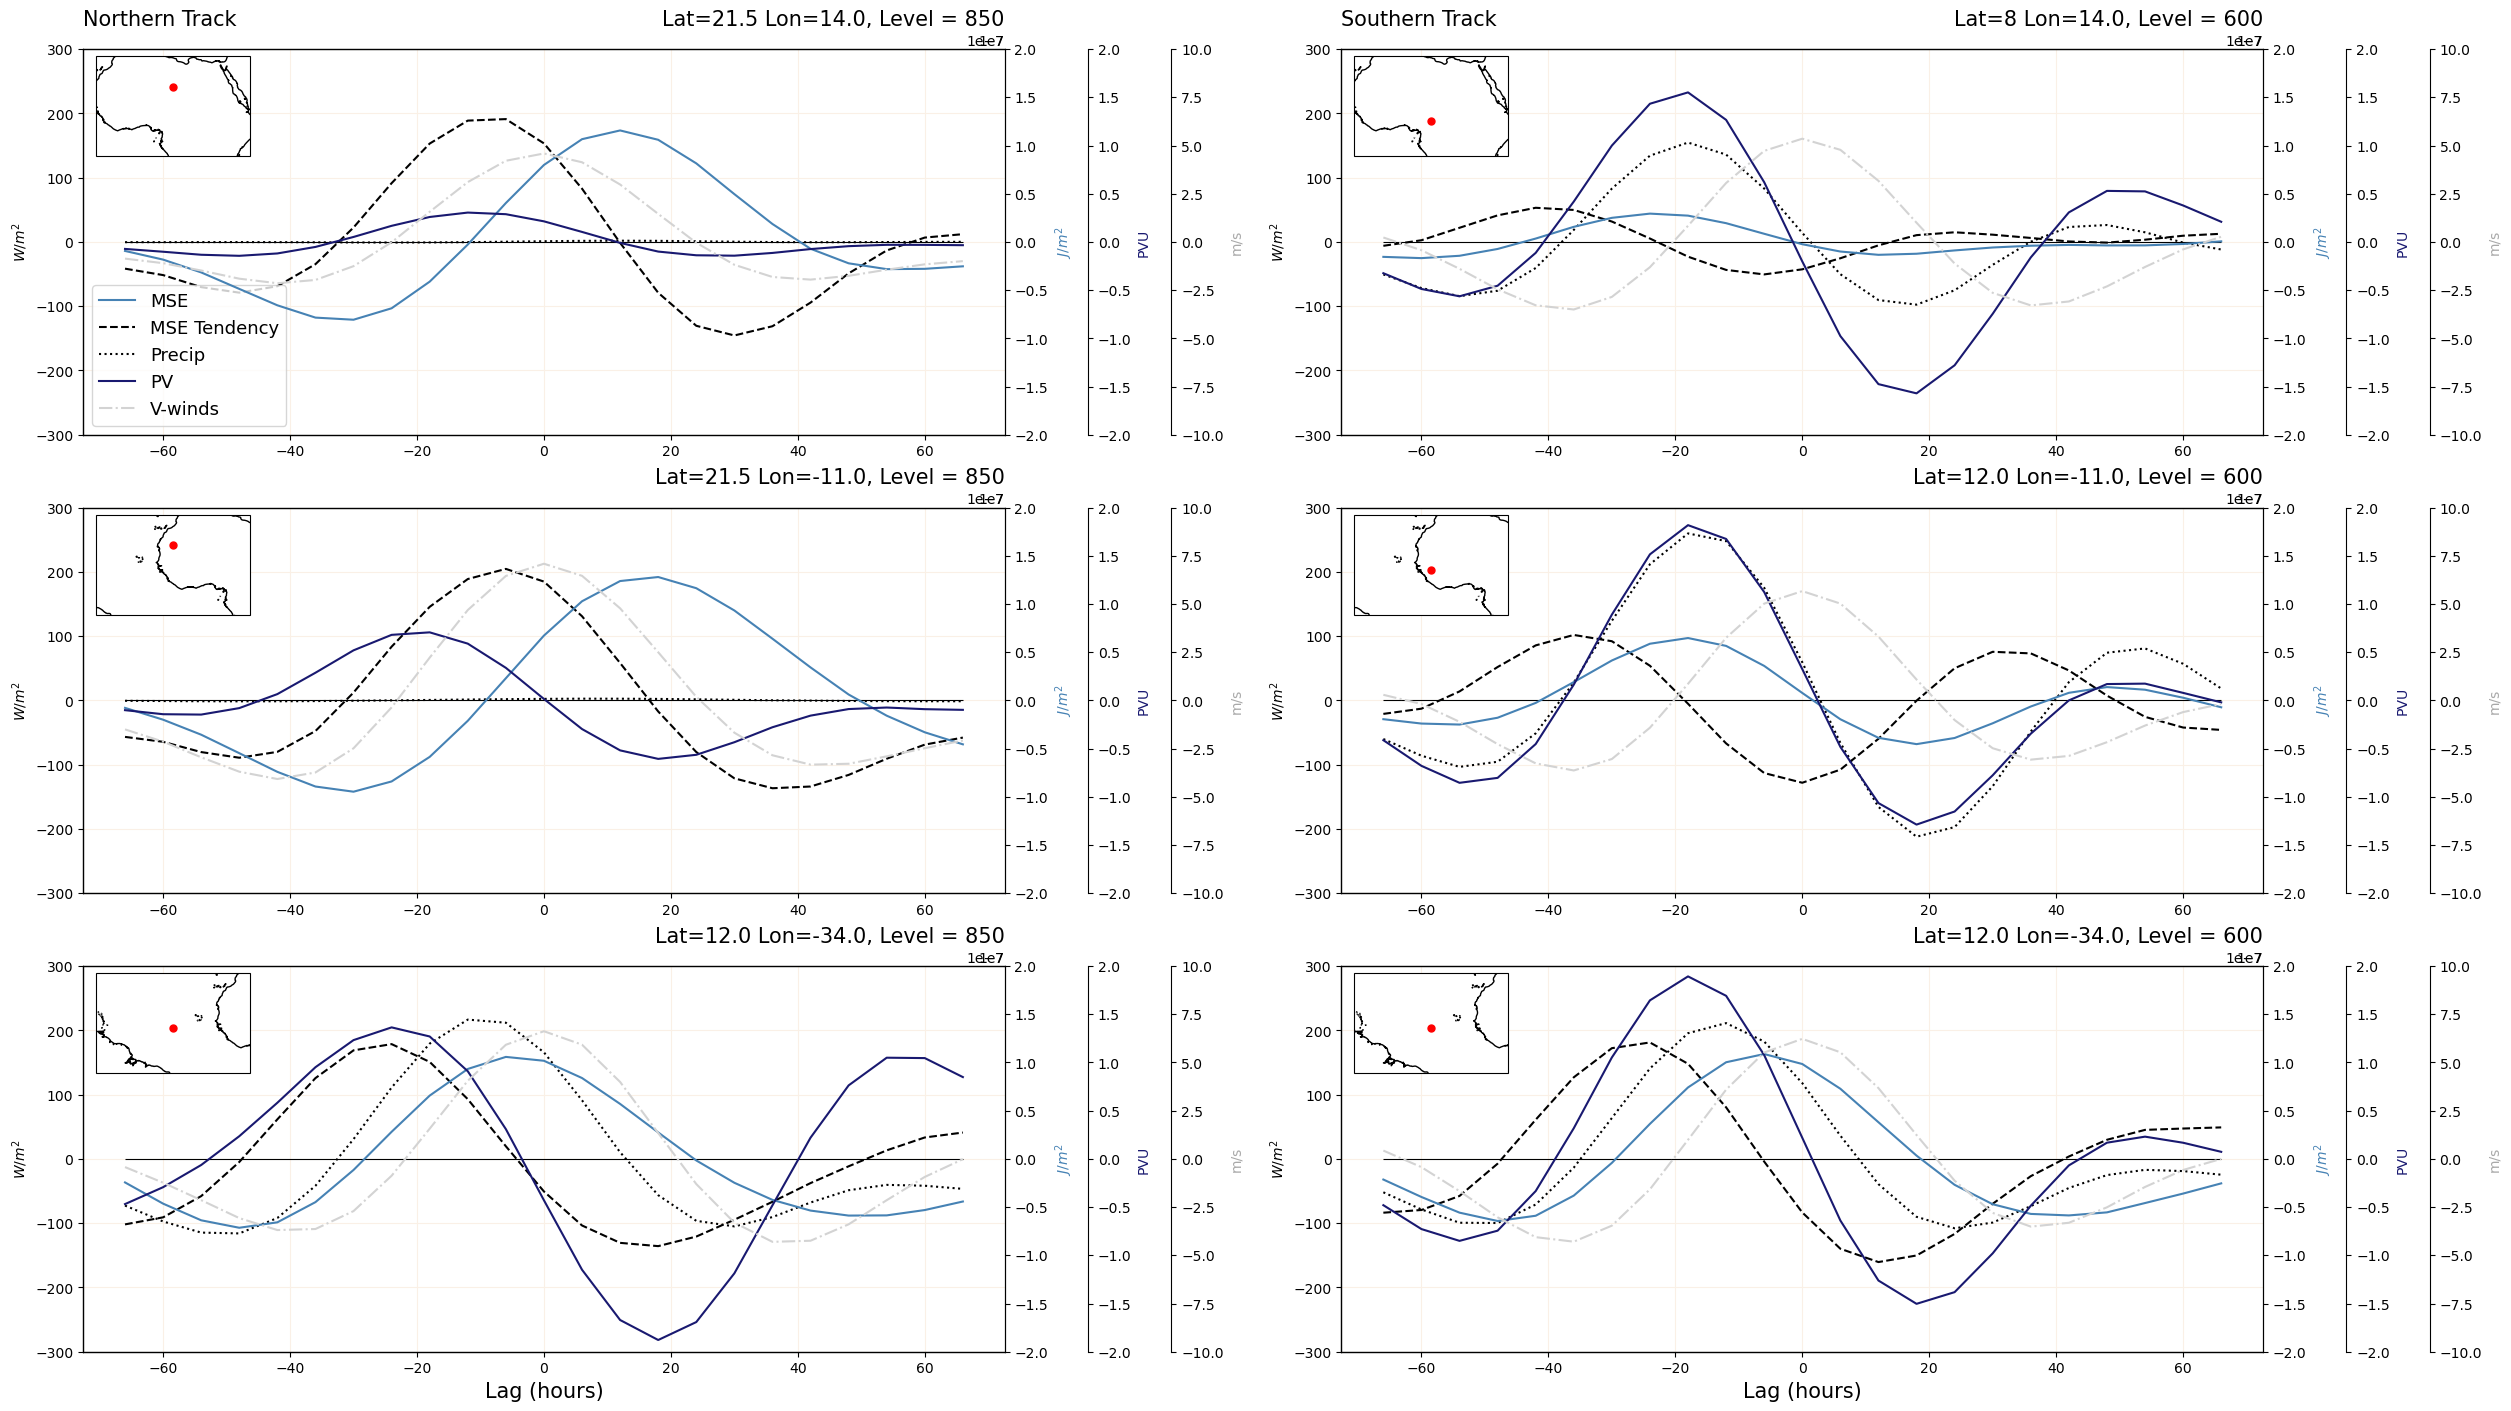

In [8]:
# plotting
fig, ax = plt.subplots(3,2, figsize=(25,14), constrained_layout=True)
ax2 = np.empty_like(ax, dtype=object)
ax3 = np.empty_like(ax, dtype=object)
ax4 = np.empty_like(ax, dtype=object)

# Image quality
plt.rcParams['savefig.dpi'] = 255
for j in range(0,2):
    for iplot in range(0,3):
        ax2[iplot, j] = ax[iplot, j].twinx()
        ax3[iplot, j] = ax[iplot, j].twinx()
        ax4[iplot, j] = ax[iplot, j].twinx()
        
        mse = get_data(variab[0], level[j], itrack[iplot], varNam[0])
        print(mse.min(), 'MSE min:')
        print(mse.max(), 'MSE max:')
        tend = np.gradient(mse, dt)
        print(tend.min(), 'tend min:')
        print(tend.max(), 'tend max:')
        pv = get_data(variab[3], level[j], itrack[iplot], varNam[3])
        #pv = np.gradient(pv, dt) # for PV tendency
        precip = get_data(variab[1], level[j], itrack[iplot], varNam[1])
        precip = precip*constants.density_water*constants.water_heat_vaporization
        precip = precip.metpy.convert_units('watts/(m**2)')
        v = get_data(variab[2], level[j], itrack[iplot], varNam[2])
        dse = get_data(variab[4], level[j], itrack[iplot], varNam[4])
        # scale v winds so they match the other values
        #scale = 30
        #pv_scale = 1.e9
        #v = v*scale
        #pv = pv*pv_scale
        
        Rtitle = 'Lat=' + str(mse.latRef) + ' Lon=' + str(mse.lonRef) + ', Level = ' +str(level[j])
        e = ax2[iplot,j].plot(range(-66, 67, 6), mse, label='MSE', color='steelblue')
        a = ax[iplot,j].plot(range(-66, 67, 6), tend, label='MSE Tendency', color='black', linestyle='--')
        b = ax[iplot,j].plot(range(-66, 67, 6), precip, label='Precip', color='black', linestyle=':')
        c = ax3[iplot,j].plot(range(-66, 67, 6), pv, label='PV', color='midnightblue')
        d = ax4[iplot,j].plot(range(-66, 67, 6), v, label='V-winds', color='lightgray', linestyle='-.')
        #ax[iplot,j].plot(range(-66, 67, 6), dse*1.e-4, label='DSE', color='darkgray', linestyle='--')
        ax[iplot,j].grid(True, color='linen')
        ax[iplot,j].hlines(y=0, xmin=-66, xmax=66, color='black', linewidth=0.8)
        #Rtitle = 'Lat=' + str(latRef) + ' Lon=' + str(lonRef) + ', Level = ' +str(level[iplot])
        # Use geocat.viz.util convenience function to set titles and labels
        gv.set_titles_and_labels(ax[iplot,j],
                             righttitle=Rtitle,                         
                             righttitlefontsize=15)
        # Add the map subplot to the existing figure
        inset_ax = inset_axes(ax[iplot,j],
                        width="18%", # width = 30% of parent_bbox
                        height=1.0, # height : 1 inch
                        loc=2, #bbox_transform=ax.transAxes,
                        axes_class=cartopy.mpl.geoaxes.GeoAxes,
                        axes_kwargs=dict(map_projection=ccrs.PlateCarree()))
        minlon = mse.lonRef - 30.
        maxlon = mse.lonRef + 30.
        minlat = -5.
        maxlat = 30.
    
        #Set the extent or specific region for the inset map
        inset_ax.set_extent([minlon, maxlon, minlat, maxlat])  

        ax3[iplot,j].spines['right'].set_position(('outward', 60))
        ax4[iplot,j].spines['right'].set_position(('outward', 120))

        #ax2[iplot,j].spines['right'].set_position(('outward', 60))
        
        ax2[iplot, j].set_ylabel('$J/m^2$', color='steelblue')
        ax[iplot, j].set_ylabel('$W/m^2$', color='black')
        ax3[iplot,j].set_ylabel('PVU', color='midnightblue')
        ax4[iplot,j].set_ylabel('m/s', color='darkgray')
        
        #Add coastlines and other features to the inset map
        inset_ax.add_feature(cfeature.COASTLINE, zorder=1)
        inset_ax.plot(mse.lonRef, mse.latRef, marker='o', markersize=5, color='red', transform=ccrs.PlateCarree())
        ax2[iplot,j].set_ylim(-2.e7,2.e7) #MSE
        ax[iplot,j].set_ylim(-300,300) #Precip
        #ax3[iplot,j].set_ylim(-20.e-8,20.e-8) #PV
        ax3[iplot,j].set_ylim(-2.e-7,2.e-7) #PV
        ax4[iplot,j].set_ylim(-10,10) #V-winds

ax[2,0].set_xlabel('Lag (hours)', fontsize=15)
ax[2,1].set_xlabel('Lag (hours)', fontsize=15)
ax[0,0].legend(handles =e+a+b+c+d,loc='lower left', fontsize=13)

gv.set_titles_and_labels(ax[0,0],
                         lefttitle=Ltitle[0],
                         lefttitlefontsize=15)
gv.set_titles_and_labels(ax[0,1],
                         lefttitle=Ltitle[1],
                         lefttitlefontsize=15)
#plt.suptitle('Lagplot of MSE & Precipitation', weight='bold', fontsize = 20)
#plt.savefig(plotsdir+'lagplot_timeseries.png')
#plt.savefig('lagplot_timeseries.png')